#### SHAP - GPU -version

This most likely requires your computer/laptop has an Nvidia GPU with CUDA -support. 

[10:31:33] WARNING: C:/Users/administrator/workspace/xgboost-win64_release_1.6.0/src/learner.cc:627: 
Parameters: { "device" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.




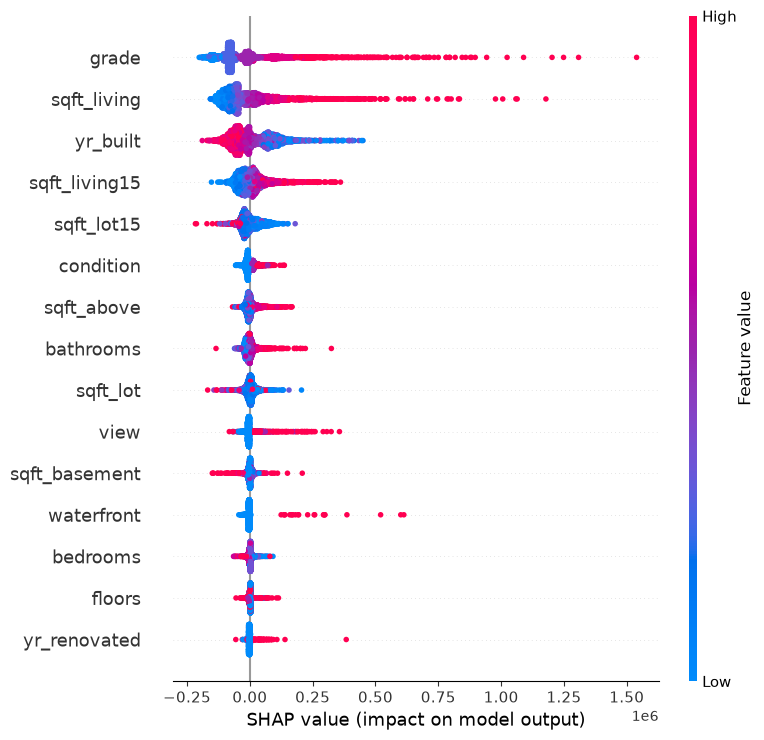

Feature Importances using SHAP:
          Feature    Importance
8           grade  95304.609375
2     sqft_living  84115.617188
11       yr_built  63710.195312
13  sqft_living15  38934.484375
14     sqft_lot15  28573.755859
7       condition  15329.841797
9      sqft_above  13814.290039
1       bathrooms  13605.244141
3        sqft_lot  13388.638672
6            view  10207.815430
10  sqft_basement   7411.572754
5      waterfront   5110.651855
0        bedrooms   4809.016113
4          floors   4352.423828
12   yr_renovated   2819.506348


In [64]:
# pip install shap
# pip install xgboost

import shap
import xgboost as xgb
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# load data
df = pd.read_csv("../houses.csv")

# handle these better with your own dataset, here we are simply dropping these
df = df.drop(['id', 'date', 'zipcode', 'lat', 'long'], axis=1)

# Define features and target
X = df[['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'sqft_living15',
       'sqft_lot15']]

y = df['price']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# use GPU-enabled XGBoost Regressor
model = xgb.XGBRegressor(tree_method='hist', device='cuda')
model.fit(X_train, y_train)

# Initialize SHAP explainer
explainer = shap.Explainer(model)
shap_values = explainer(X_test)

# Plot SHAP summary
shap.summary_plot(shap_values, X_test)

# Feature importance using SHAP values
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': np.mean(np.abs(shap_values.values), axis=0)  # shap_values.values for the matrix
})

print("Feature Importances using SHAP:")
print(importance.sort_values('Importance', ascending=False))


In [65]:
# TODO add some regression metrics in order to evaluate if the model is even good or not
# SHAP values not that useful if the model is not very good, although it gives us the idea
# that the dataset needs to be improved still

___

### More experimental additional SHAP visualizations

Combination of AI, documentation and Googling

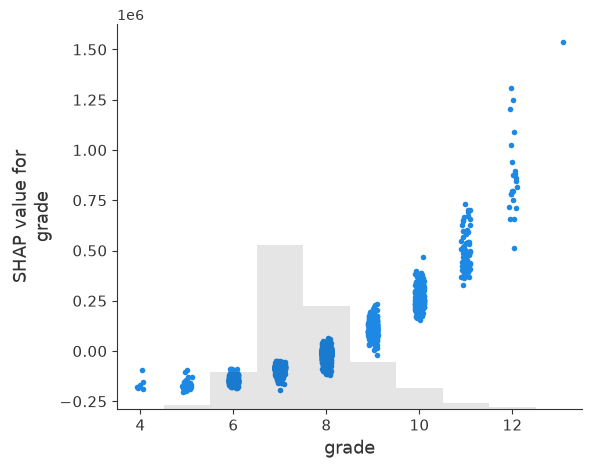

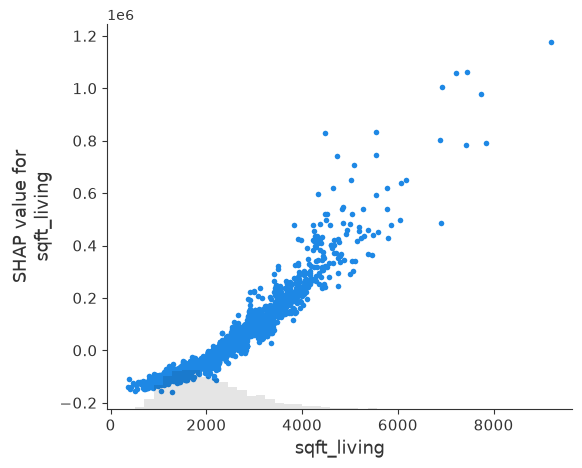

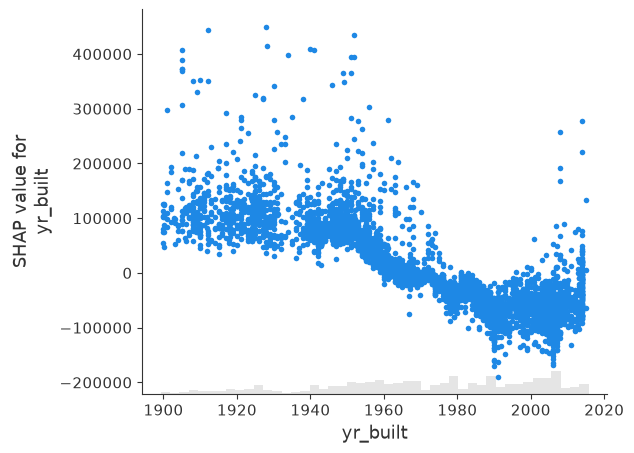

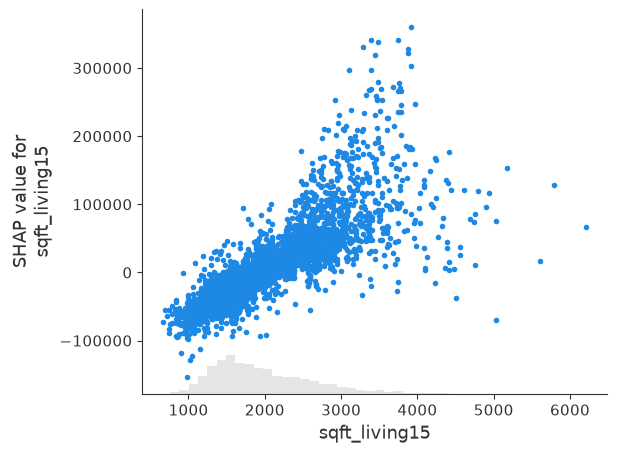

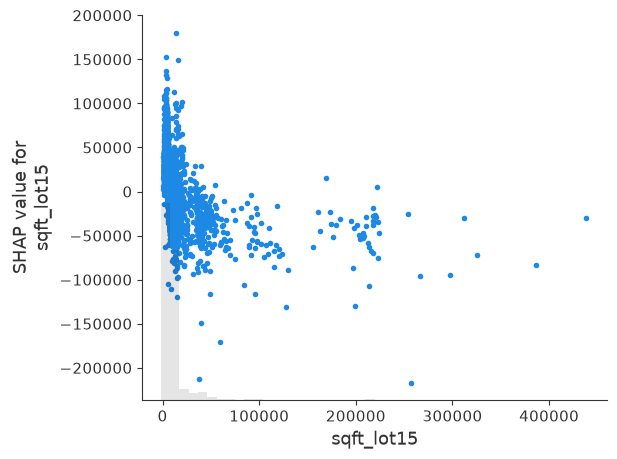

In [66]:
# Top 5 features from SHAP importance
top_features = importance.sort_values(by="Importance", ascending=False).Feature.values[:5]

for feature in top_features:
    shap.plots.scatter(shap_values[:, feature])


In [67]:
X_test.iloc[123]

bedrooms             5.0
bathrooms            3.5
sqft_living       3960.0
sqft_lot         25245.0
floors               2.0
waterfront           0.0
view                 0.0
condition            3.0
grade                9.0
sqft_above        2500.0
sqft_basement     1460.0
yr_built          1996.0
yr_renovated         0.0
sqft_living15     2640.0
sqft_lot15       13675.0
Name: 156, dtype: float64

In [68]:
y_test.iloc[123]

np.float64(650000.0)

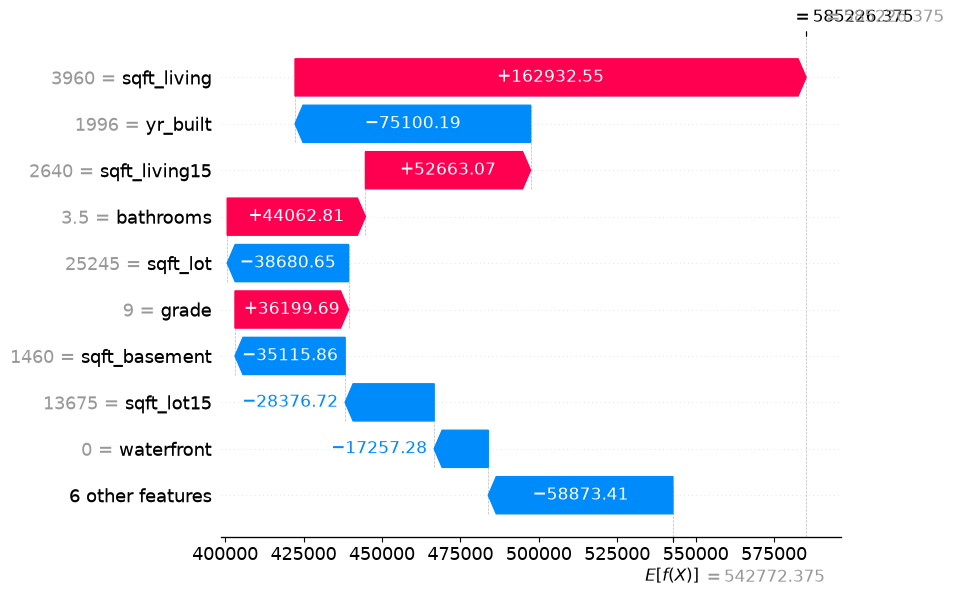

In [69]:
shap.plots.waterfall(shap_values[123])

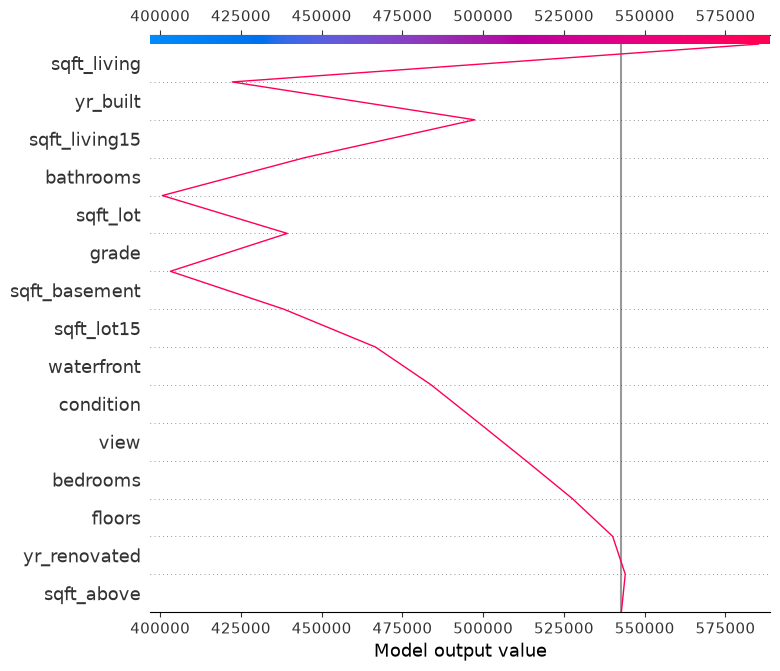

In [70]:
index = 123

shap.plots.decision(
    base_value=shap_values.base_values[index],
    shap_values=shap_values.values[index],
    feature_names=list(X_test.columns),
)


In [71]:
shap.initjs()

# For example, create a force plot for the first test instance:
shap.plots.force(
    base_value=shap_values.base_values[0],
    shap_values=shap_values.values[0],
    features=X_test.iloc[0],
    feature_names=list(X_test.columns)
)

### Feature interactions, seems useful on determining which variables are connected (outside the target)

**This plot looks promising, but might have bugs, not thoroughly tested**

Also careful when using these, pay attention to the variables you compare to each other.

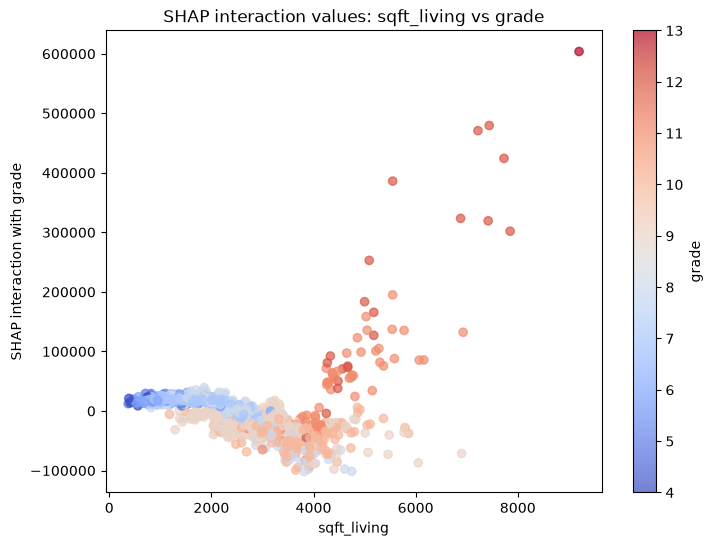

In [73]:
# a more simple version of the code above...
# needs still more testing if this actually works. 
# probably would be easiest to have a much more simple dataset
# and to test how it behaves here
import matplotlib.pyplot as plt

feature_1 = 'sqft_living'
feature_2 = 'grade'

shap_interaction_values = explainer.shap_interaction_values(X_test)

# Indices of the two features
i = X_test.columns.get_loc(feature_1)
j = X_test.columns.get_loc(feature_2)

# Extract values
interaction_vals = shap_interaction_values[:, i, j]
feat1_vals = X_test.iloc[:, i]
feat2_vals = X_test.iloc[:, j]

# Plot
plt.figure(figsize=(8, 6))
sc = plt.scatter(feat1_vals, interaction_vals, c=feat2_vals, cmap='coolwarm', alpha=0.7)
plt.xlabel(feature_1)
plt.ylabel('SHAP interaction with ' + feature_2)
plt.colorbar(sc, label=feature_2)
plt.title(f'SHAP interaction values: {feature_1} vs {feature_2}')
plt.show()


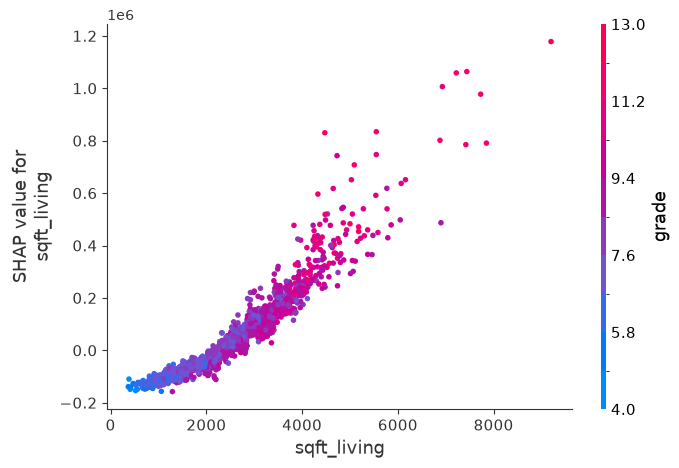

In [75]:
# a more simple version of the code above

# Example with TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Then plot
shap.dependence_plot(
    feature_1,            # can be index or name
    shap_values,          # 2D array [n_samples, n_features]
    X_test,               # DataFrame or array with feature names
    interaction_index=feature_2  # optional
)


In [76]:
from sklearn import metrics

predictions = model.predict(X_test)

# MAE - Mean average error
print("MAE")
print(round(metrics.mean_absolute_error(y_test, predictions), 2), "$")

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(y_test, predictions)), 2), "$")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(y_test, predictions), 2))

# mean house price is 540k$, range is between 75 000 to 7.7 million USD

MAE
114983.63 $

RMSE:
175047.65 $

R-squared:
0.74


In [77]:
df.describe()['price'].astype(int)

# mean house price is 540k$, range is between 75 000 to 7.7 million USD

count      21613
mean      540088
std       367127
min        75000
25%       321950
50%       450000
75%       645000
max      7700000
Name: price, dtype: int64